In [1]:
import pandas as pd
import os

# อ่านไฟล์ข้อมูล
file_path = "c:\\Users\\supin\\Downloads\\tourists_all.csv"
df = pd.read_csv(file_path)

# 1. ตรวจสอบขนาดข้อมูล
print("===== ขนาดข้อมูล =====")
print("จำนวนแถว:", df.shape[0])
print("จำนวนคอลัมน์:", df.shape[1])

# 2. ตรวจสอบชื่อคอลัมน์
print("\n===== ชื่อคอลัมน์ =====")
print(df.columns.tolist())

# 3. แสดงข้อมูล 5 แถวแรก
print("\n===== ตัวอย่างข้อมูล =====")
print(df.head())

# 4. ตรวจสอบชนิดข้อมูล
print("\n===== ชนิดข้อมูล =====")
print(df.dtypes)

# 5. ตรวจสอบค่าว่าง
print("\n===== จำนวนค่าว่าง =====")
print(df.isnull().sum())

# 6. ตรวจสอบข้อมูลซ้ำ
print("\n===== ข้อมูลซ้ำ =====")
print("จำนวนแถวซ้ำ:", df.duplicated().sum())

===== ขนาดข้อมูล =====
จำนวนแถว: 30048
จำนวนคอลัมน์: 5

===== ชื่อคอลัมน์ =====
['date', 'continent', 'Region', 'Country', 'Number']

===== ตัวอย่างข้อมูล =====
                  date continent              Region        Country Number
0  2015-01-01T00:00:00    Africa        North africa        Morocco    498
1  2015-01-01T00:00:00    Africa  Sub-Saharan Africa  South  Africa  5,154
2  2015-01-01T00:00:00    Africa  Sub-Saharan Africa       Ethiopia    621
3  2015-01-01T00:00:00    Africa  Sub-Saharan Africa          Kenya    357
4  2015-01-01T00:00:00    Africa  Sub-Saharan Africa      Mauritius    469

===== ชนิดข้อมูล =====
date         str
continent    str
Region       str
Country      str
Number       str
dtype: object

===== จำนวนค่าว่าง =====
date         0
continent    0
Region       0
Country      0
Number       0
dtype: int64

===== ข้อมูลซ้ำ =====
จำนวนแถวซ้ำ: 0


In [2]:
# 1. ตรวจสอบค่าที่อยู่ในคอลัมน์ Number
print(df["Number"].head(10))

# 2. ลบเครื่องหมายจุลภาคออก
df["Number"] = df["Number"].str.replace(",", "", regex=False)

# 3. เปลี่ยนเครื่องหมาย - เป็นค่าว่าง
df["Number"] = df["Number"].replace("-", pd.NA)

# 4. แปลงข้อมูลให้เป็นตัวเลข
df["Number"] = pd.to_numeric(df["Number"], errors="coerce")

# 5. ตรวจสอบผลลัพธ์
print("\n===== ผลหลังทำความสะอาด =====")
print(df["Number"].head(10))
print("\nชนิดข้อมูล:", df["Number"].dtype)
print("จำนวนค่า NaN:", df["Number"].isnull().sum())

0      498
1    5,154
2      621
3      357
4      469
5      182
6      394
7      385
8       57
9       31
Name: Number, dtype: str

===== ผลหลังทำความสะอาด =====
0     498.0
1    5154.0
2     621.0
3     357.0
4     469.0
5     182.0
6     394.0
7     385.0
8      57.0
9      31.0
Name: Number, dtype: float64

ชนิดข้อมูล: float64
จำนวนค่า NaN: 9732


In [4]:
print(df["date"].head(15))


0     2015-01-01T00:00:00
1     2015-01-01T00:00:00
2     2015-01-01T00:00:00
3     2015-01-01T00:00:00
4     2015-01-01T00:00:00
5     2015-01-01T00:00:00
6     2015-01-01T00:00:00
7     2015-01-01T00:00:00
8     2015-01-01T00:00:00
9     2015-01-01T00:00:00
10    2015-01-01T00:00:00
11    2015-01-01T00:00:00
12    2015-01-01T00:00:00
13    2015-01-01T00:00:00
14    2015-01-01T00:00:00
Name: date, dtype: str


In [6]:
print(df["date"].iloc[100])
print(df["date"].iloc[500])
print(df["date"].iloc[1000])

2015-01-01T00:00:00
2015-01-02T00:00:00
2015-01-04T00:00:00


In [8]:
print(df["date"].tail(10))

30038    2023-01-12T00:00:00
30039    2023-01-12T00:00:00
30040    2023-01-12T00:00:00
30041    2023-01-12T00:00:00
30042    2023-01-12T00:00:00
30043    2023-01-12T00:00:00
30044    2023-01-12T00:00:00
30045    2023-01-12T00:00:00
30046    2023-01-12T00:00:00
30047    2023-01-12T00:00:00
Name: date, dtype: str


In [10]:
# แยกปี
df["Year"] = df["date"].str[:4].astype(int)

# แยกวันที่
df["Day"] = df["date"].str[5:7].astype(int)

# แยกเดือน
df["Month"] = df["date"].str[8:10].astype(int)

# สร้างไตรมาส
df["Quarter"] = ((df["Month"] - 1) // 3) + 1

# แสดงผลตรวจสอบ
print(df[["date", "Year", "Day", "Month", "Quarter"]].head())

                  date  Year  Day  Month  Quarter
0  2015-01-01T00:00:00  2015    1      1        1
1  2015-01-01T00:00:00  2015    1      1        1
2  2015-01-01T00:00:00  2015    1      1        1
3  2015-01-01T00:00:00  2015    1      1        1
4  2015-01-01T00:00:00  2015    1      1        1


In [12]:
print(df["Month"].value_counts().sort_index())

Month
1     2504
2     2504
3     2504
4     2504
5     2504
6     2504
7     2504
8     2504
9     2504
10    2504
11    2504
12    2504
Name: count, dtype: int64


In [14]:
print(df["date"].iloc[0])
print(df["date"].iloc[2504])
print(df["date"].iloc[5008])

2015-01-01T00:00:00
2015-01-09T00:00:00
2016-01-06T00:00:00


In [16]:
print(df[["date", "Country", "Number"]].iloc[2498:2510])

                     date             Country  Number
2498  2015-01-09T00:00:00           Gibraltar     NaN
2499  2015-01-09T00:00:00              Utopia     NaN
2500  2015-01-09T00:00:00  Vatican City State     NaN
2501  2015-01-09T00:00:00        France  Mtr.     NaN
2502  2015-01-09T00:00:00     Channel Islands     NaN
2503  2015-01-09T00:00:00          Yugoslavia     1.0
2504  2015-01-09T00:00:00             Bahrain  3908.0
2505  2015-01-09T00:00:00               Egypt  3074.0
2506  2015-01-09T00:00:00                Iraq   316.0
2507  2015-01-09T00:00:00              Jordan  1221.0
2508  2015-01-09T00:00:00              Kuwait  6780.0
2509  2015-01-09T00:00:00             Lebanon   814.0


In [19]:
# แยกปี
df["Year"] = df["date"].str[:4].astype(int)

# แยกวันที่
df["Day"] = df["date"].str[5:7].astype(int)

# แยกเดือน
df["Month"] = df["date"].str[8:10].astype(int)

# สร้างไตรมาส
df["Quarter"] = ((df["Month"] - 1) // 3) + 1

# ตรวจสอบผลลัพธ์
print(df[["date", "Year", "Day", "Month", "Quarter"]].head())

                  date  Year  Day  Month  Quarter
0  2015-01-01T00:00:00  2015    1      1        1
1  2015-01-01T00:00:00  2015    1      1        1
2  2015-01-01T00:00:00  2015    1      1        1
3  2015-01-01T00:00:00  2015    1      1        1
4  2015-01-01T00:00:00  2015    1      1        1


In [21]:
# หาผลรวมนักท่องเที่ยวแยกตามปีและไตรมาส
quarter_total = df.groupby(
    ["Year", "Quarter"]
)["Number"].sum(min_count=1)

# แสดงผลลัพธ์
print(quarter_total)

Year  Quarter
2015  1           7833277.0
      2           6977875.0
      3           7275824.0
      4           7836209.0
2016  1           9004203.0
      2           7509900.0
      3           8249517.0
      4           7765968.0
2017  1           9181986.0
      2           8184984.0
      3           8887836.0
      4           9337172.0
2018  1          10578247.0
      2           8847205.0
      3           9042234.0
      4           9710508.0
2019  1          10792781.0
      2           9010224.0
      3           9705444.0
      4          10407802.0
2020  1           6691574.0
      2                 NaN
      3                 NaN
      4             33619.0
2021  1             38342.0
      2             34706.0
      3             65835.0
      4            371884.0
2022  1            488118.0
      2           1564658.0
      3           3582421.0
      4           5430029.0
2023  1           6528231.0
      2           6437153.0
      3           7089281.0
      

In [24]:
quarter_total.loc[(2020, 2)] = 0
quarter_total.loc[(2020, 3)] = 0

print(quarter_total)

Year  Quarter
2015  1           7833277.0
      2           6977875.0
      3           7275824.0
      4           7836209.0
2016  1           9004203.0
      2           7509900.0
      3           8249517.0
      4           7765968.0
2017  1           9181986.0
      2           8184984.0
      3           8887836.0
      4           9337172.0
2018  1          10578247.0
      2           8847205.0
      3           9042234.0
      4           9710508.0
2019  1          10792781.0
      2           9010224.0
      3           9705444.0
      4          10407802.0
2020  1           6691574.0
      2                 0.0
      3                 0.0
      4             33619.0
2021  1             38342.0
      2             34706.0
      3             65835.0
      4            371884.0
2022  1            488118.0
      2           1564658.0
      3           3582421.0
      4           5430029.0
2023  1           6528231.0
      2           6437153.0
      3           7089281.0
      

In [33]:

# เปลี่ยนค่าว่างในคอลัมน์ Number เป็น 0
df["Number"] = df["Number"].fillna(0)

# ตรวจสอบจำนวนค่าว่างที่เหลือ
print(df["Number"].isna().sum())


0


In [34]:

print(df.info())
print(df.head())


<class 'pandas.DataFrame'>
RangeIndex: 30048 entries, 0 to 30047
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       30048 non-null  str    
 1   continent  30048 non-null  str    
 2   Region     30048 non-null  str    
 3   Country    30048 non-null  str    
 4   Number     30048 non-null  float64
 5   Year       30048 non-null  int64  
 6   Day        30048 non-null  int64  
 7   Month      30048 non-null  int64  
 8   Quarter    30048 non-null  int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 2.1 MB
None
                  date continent              Region        Country  Number  \
0  2015-01-01T00:00:00    Africa        North africa        Morocco   498.0   
1  2015-01-01T00:00:00    Africa  Sub-Saharan Africa  South  Africa  5154.0   
2  2015-01-01T00:00:00    Africa  Sub-Saharan Africa       Ethiopia   621.0   
3  2015-01-01T00:00:00    Africa  Sub-Saharan Africa          Kenya   357.0   
4  20

In [36]:
# รวมจำนวนนักท่องเที่ยวจากข้อมูลดิบแยกตามปี
year_total = df.groupby("Year")["Number"].sum(min_count=1)

# กำหนดไตรมาส 2 และ 3 ของปี 2020 เป็น 0 ตามสมมติฐานเดิม
year_total.loc[2020] = quarter_total.loc[2020].sum(min_count=1)

print(year_total)

Year
2015    29923185.0
2016    32529588.0
2017    35591978.0
2018    38178194.0
2019    39916251.0
2020     6725193.0
2021      510767.0
2022    11065226.0
2023    28150016.0
Name: Number, dtype: float64


In [37]:
!pip install matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


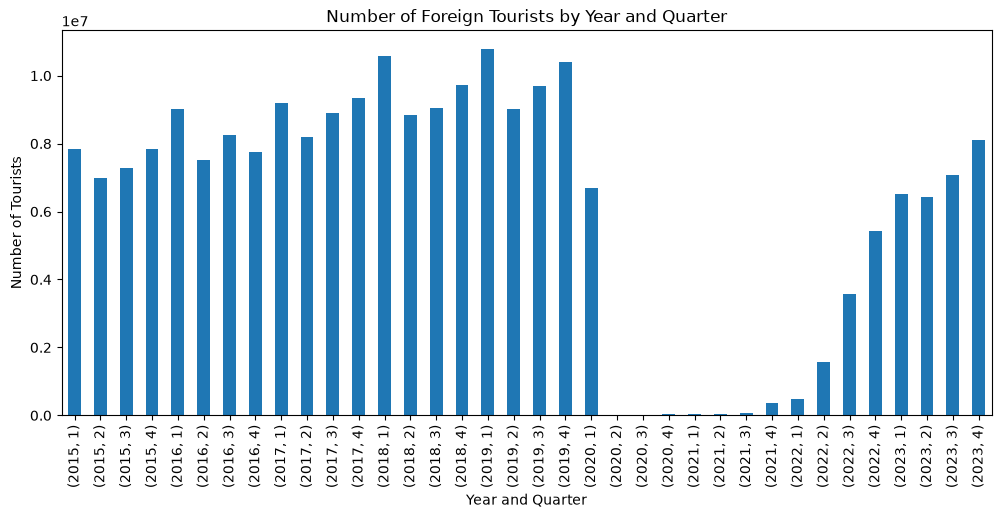

In [38]:
import matplotlib.pyplot as plt

quarter_total.plot(kind="bar", figsize=(12, 5))

plt.title("Number of Foreign Tourists by Year and Quarter")
plt.xlabel("Year and Quarter")
plt.ylabel("Number of Tourists")

plt.show()

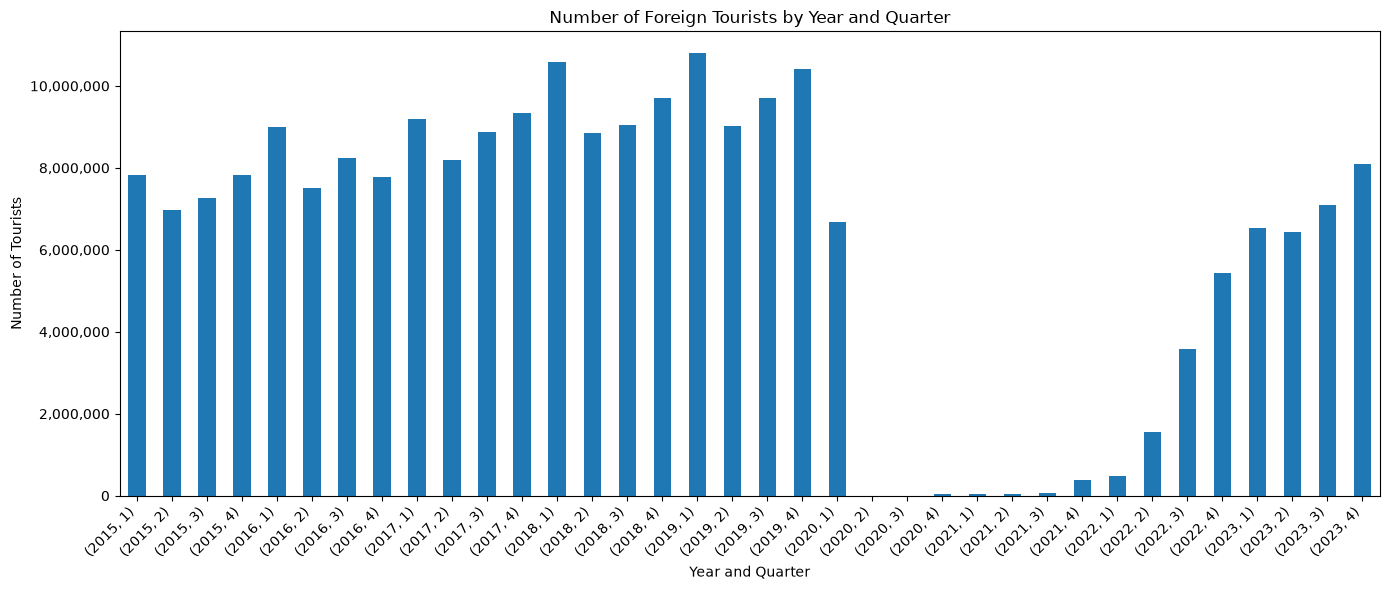

In [69]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ax = quarter_total.plot(kind="bar", figsize=(14, 6))

ax.set_title("Number of Foreign Tourists by Year and Quarter")
ax.set_xlabel("Year and Quarter")
ax.set_ylabel("Number of Tourists")

# แสดงตัวเลขแกนตั้งพร้อมเครื่องหมายคั่นหลักพัน
ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [42]:
print(year_total.apply(lambda x: format(x, ",.0f")))

Year
2015    29,923,185
2016    32,529,588
2017    35,591,978
2018    38,178,194
2019    39,916,251
2020     6,725,193
2021       510,767
2022    11,065,226
2023    28,150,016
Name: Number, dtype: str


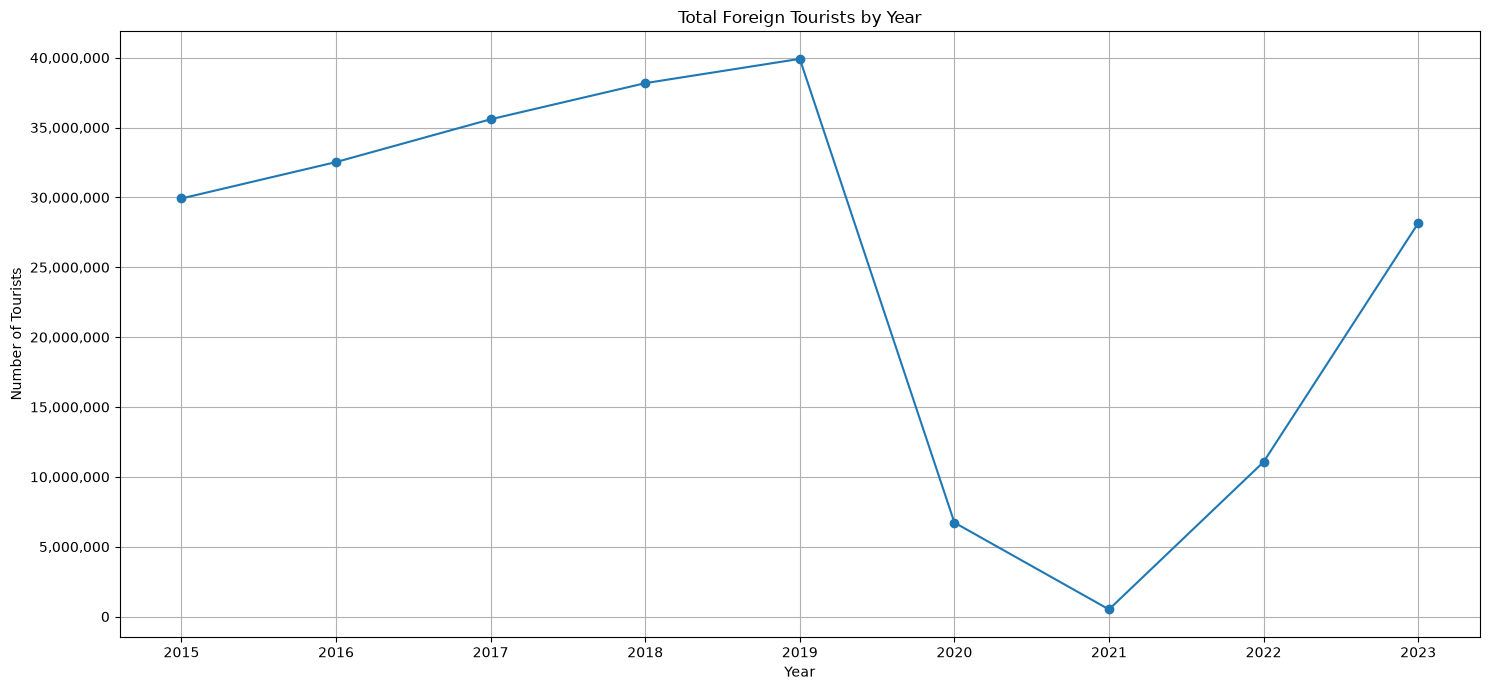

In [46]:

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

year_total.plot(kind="line", marker="o", figsize=(15, 7))

plt.title("Total Foreign Tourists by Year")
plt.xlabel("Year")
plt.ylabel("Number of Tourists")
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)
plt.grid(True)
plt.tight_layout()
plt.show()


In [70]:
# คำนวณเปอร์เซ็นต์การเปลี่ยนแปลงจากปีก่อน
change_percent = year_total.pct_change() * 100

print(change_percent.round(2))

Year
2015        NaN
2016       8.71
2017       9.41
2018       7.27
2019       4.55
2020     -83.15
2021     -92.41
2022    2066.39
2023     154.40
Name: Number, dtype: float64


In [51]:

country_total = df.groupby("Country")["Number"].sum()

# เรียงจากจำนวนมากไปน้อย เลือก 10 ประเทศแรก
top10 = country_total.sort_values(ascending=False).head(10)

print(top10.apply(lambda x: format(x, ",.0f")))


Country
China                           53,479,693
Malaysia                        25,920,714
Korea (Republic of)             10,645,325
India                            9,808,617
Laos                             9,666,414
Japan                            9,154,044
Russian Federation               8,779,274
Singapore                        7,593,754
The United States of America     6,625,567
Vietnam                          6,376,779
Name: Number, dtype: str


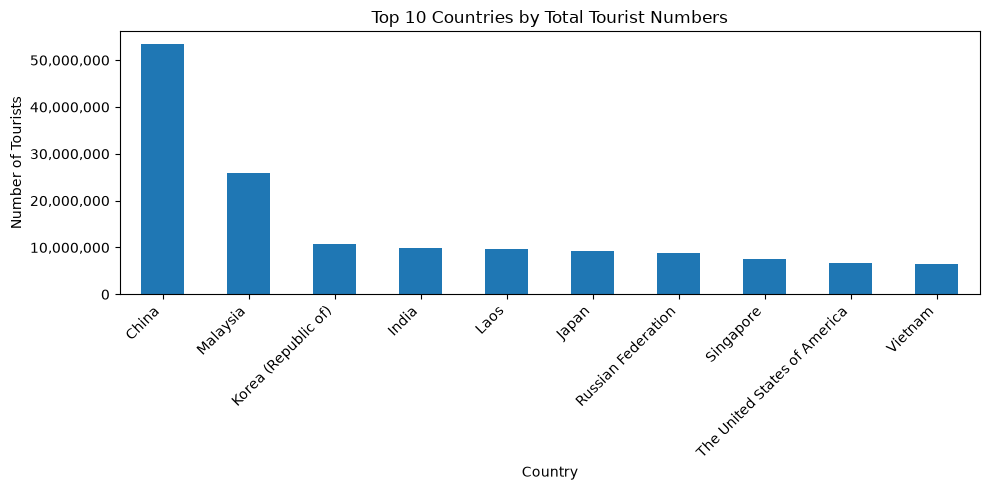

In [63]:

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

top10.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Total Tourist Numbers")
plt.xlabel("Country")
plt.ylabel("Number of Tourists")
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


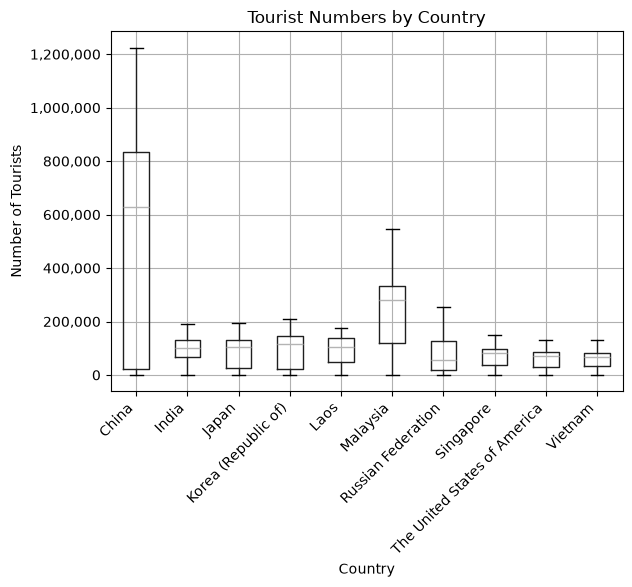

In [71]:

import matplotlib.pyplot as plt

top5 = df[df["Country"].isin(top10.index)]

top5.boxplot(column="Number", by="Country")

plt.title("Tourist Numbers by Country")
plt.suptitle("")
plt.xlabel("Country")
plt.ylabel("Number of Tourists")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=45,ha="right")
plt.show()


In [72]:
# คำนวณสถิติพื้นฐานของจำนวนนักท่องเที่ยวแยกตามปี
stats_by_year = df.groupby('Year')['Number'].agg([
    ('ยอดรวม (Sum)', 'sum'),
    ('ค่าเฉลี่ย (Mean)', 'mean'),
    ('ค่ามัธยฐาน (Median)', 'median'),
    ('สูงสุด (Max)', 'max'),
    ('ส่วนเบี่ยงเบนมาตรฐาน (Std)', 'std')
])

# จัดรูปแบบตัวเลขให้แสดงผลสวยงามมีคอมมาคั่น
pd.options.display.float_format = '{:,.2f}'.format
print("===== สถิติจำนวนนักท่องเที่ยวแยกตามปี (2015-2023) =====")
print(stats_by_year.to_string())

===== สถิติจำนวนนักท่องเที่ยวแยกตามปี (2015-2023) =====
      ยอดรวม (Sum)  ค่าเฉลี่ย (Mean)  ค่ามัธยฐาน (Median)  สูงสุด (Max)  ส่วนเบี่ยงเบนมาตรฐาน (Std)
Year                                                                                               
2015 29,923,185.00          8,905.71                42.00    804,467.00                   46,732.34
2016 32,529,588.00          9,681.42                41.00    982,527.00                   51,573.89
2017 35,591,978.00         10,592.85                44.00    948,243.00                   56,190.39
2018 38,178,194.00         11,362.56                44.50  1,224,481.00                   61,688.62
2019 39,916,251.00         11,879.84                46.50  1,079,300.00                   64,372.86
2020  6,725,193.00          2,001.55                 0.00  1,053,807.00                   22,655.59
2021    510,767.00            152.01                 1.00     25,697.00                      984.68
2022 11,065,226.00          3,390.08        